# C1_11_Time_Trend
- Y = y_labels_c1_v2.csv
- Test predictions = `test_pred.npy` and `test_idx.npy` from C1_09_Test_Evaluation
- Class order = `scaler_and_classes.npz` from C1_08_Final_Model

### Does the model show a trend over the years?

**Purpose:** for each year, the share of windows (%) that the final model predicts as Improving, Base, Declining or Recovery, next to the share the labels give for the same windows. Each run's shares are worked out first and then averaged, so a long run does not count more than a short one.

This uses the 375 test runs, which the model never saw, and the predictions saved by C1_09_Test_Evaluation. No model is run here. The last section reports how well the model does on these unseen runs, by year. 2017 starts in April and 2026 ends in July, so both are partial years. These show association in this data, not cause.

## 1. Setup and configuration

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed")
Y_PATH = DATA_DIR / "y_labels_c1_v2.csv"
MODEL_DIR = DATA_DIR / "c1_final_model"                  # output of C1_08_Final_Model
TEST_DIR = MODEL_DIR / "test_evaluation"                 # output of C1_09_Test_Evaluation
OUT_DIR = DATA_DIR / "c1_time_trend"
OUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_SECONDS = 30       # length of one window
MIN_RUN_MINUTES = 20      # shorter runs are left out

## 2. Load the test predictions

`test_idx.npy` lists which windows are the test windows, and `test_pred.npy` holds the model's prediction for each. The actual label for each window comes from the Y file.

In [2]:
y_df = pd.read_csv(Y_PATH, parse_dates=["date"])
test_idx = np.load(TEST_DIR / "test_idx.npy")
test_pred = np.load(TEST_DIR / "test_pred.npy")
classes = np.load(MODEL_DIR / "scaler_and_classes.npz")["classes"]
assert len(test_idx) == len(test_pred), "predictions and test windows differ in length"

test = y_df.iloc[test_idx][["run_idx", "date", "c1_target"]].rename(columns={"c1_target": "actual"})
test["predicted"] = classes[test_pred]
print(f"{len(test)} test windows from {test['run_idx'].nunique()} runs, {test['date'].min().date()} to {test['date'].max().date()}")
print(f"Accuracy on these windows: {(test['actual'] == test['predicted']).mean():.3f}")

39080 test windows from 375 runs, 2017-05-31 to 2026-06-22
Accuracy on these windows: 0.605


## 3. Runs of at least 20 minutes

A run's length is worked out from its last window, so very short runs, which have too few windows for a reliable share, are left out.

In [3]:
run_minutes = (y_df.groupby("run_idx")["start_s"].max() + 2 * WINDOW_SECONDS) / 60     # about how long each run was
test = test[test["run_idx"].map(run_minutes) >= MIN_RUN_MINUTES]
print(f"{test['run_idx'].nunique()} runs of at least {MIN_RUN_MINUTES} minutes, {len(test)} windows")

339 runs of at least 20 minutes, 38342 windows


## 4. Share of windows in each class, by year

Each row is the average, over that year's runs, of the share (%) of a run's windows in each class. The first table is what the model predicted, and the second is what the labels say for the same windows.

In [4]:
order = ["Improving", "Base", "Declining", "Recovery"]
run_year = test.groupby("run_idx")["date"].first().dt.year


def share_by_year(column):
    shares = pd.crosstab(test["run_idx"], test[column], normalize="index") * 100     # one row per run
    shares = shares.reindex(columns=order, fill_value=0)
    shares["year"] = run_year
    return shares.groupby("year")[order].mean()                                        # one row per year


model_by_year = share_by_year("predicted")
actual_by_year = share_by_year("actual")
model_by_year.insert(0, "runs", run_year.value_counts().sort_index())
actual_by_year.insert(0, "runs", run_year.value_counts().sort_index())
model_by_year.round(1).to_csv(OUT_DIR / "model_share_by_year.csv")
actual_by_year.round(1).to_csv(OUT_DIR / "actual_share_by_year.csv")

print("Model: average share of windows (%) predicted in each class, by year")
print(model_by_year.round(1).to_string())
print("\nLabels: average share of windows (%) in each class, by year (same windows)")
print(actual_by_year.round(1).to_string())

Model: average share of windows (%) predicted in each class, by year
predicted  runs  Improving  Base  Declining  Recovery
year                                                 
2017         18       27.2  38.6       33.9       0.3
2018         40       25.3  43.9       29.5       1.3
2019         46       28.1  31.0       38.7       2.3
2020         36       27.9  44.5       26.7       0.9
2021         32       20.7  49.7       29.4       0.3
2022         29       22.5  51.7       25.7       0.1
2023         34       21.6  56.3       19.8       2.4
2024         39       17.6  62.0       19.4       1.1
2025         38       23.1  55.4       20.2       1.3
2026         27       20.1  47.2       29.6       3.0

Labels: average share of windows (%) in each class, by year (same windows)
actual  runs  Improving  Base  Declining  Recovery
year                                              
2017      18       30.7  32.8       35.8       0.6
2018      40       29.3  39.2       30.5       1.1
201

## 5. Chart

The solid lines are the model's predicted shares and the dashed lines are the labels for the same windows. Recovery is left out because it is only 1 to 3% of windows.

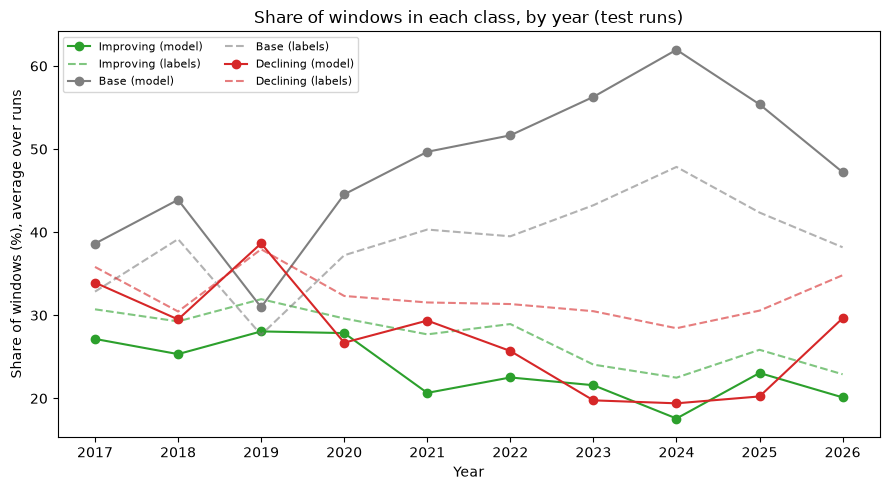

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, colour in [("Improving", "tab:green"), ("Base", "tab:grey"), ("Declining", "tab:red")]:
    ax.plot(model_by_year.index, model_by_year[name], marker="o", color=colour, label=f"{name} (model)")
    ax.plot(actual_by_year.index, actual_by_year[name], linestyle="--", color=colour, alpha=0.6, label=f"{name} (labels)")
ax.set_xticks(model_by_year.index)
ax.set_xlabel("Year")
ax.set_ylabel("Share of windows (%), average over runs")
ax.set_title("Share of windows in each class, by year (test runs)")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "share_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. How well does the model do on these unseen runs?

The accuracy of the model's predictions on the test runs, overall and for each year. Each window counts once, so a year with more windows weighs more within that year.

In [6]:
test["correct"] = test["actual"] == test["predicted"]
accuracy_by_year = test.groupby(test["date"].dt.year).agg(runs=("run_idx", "nunique"), windows=("correct", "size"), accuracy=("correct", "mean"))
accuracy_by_year.round(3).to_csv(OUT_DIR / "accuracy_by_year.csv")

print(f"Accuracy on the unseen test runs: {test['correct'].mean():.3f} ({len(test)} windows from {test['run_idx'].nunique()} runs of at least {MIN_RUN_MINUTES} minutes)\n")
print("Accuracy by year:")
print(accuracy_by_year.round(3).to_string())

Accuracy on the unseen test runs: 0.605 (38342 windows from 339 runs of at least 20 minutes)

Accuracy by year:
      runs  windows  accuracy
date                         
2017    18     2177     0.566
2018    40     4557     0.553
2019    46     5853     0.607
2020    36     3732     0.575
2021    32     3472     0.622
2022    29     3059     0.624
2023    34     3736     0.619
2024    39     4518     0.624
2025    38     3950     0.609
2026    27     3288     0.650
